In [7]:
import glob
import pickle
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle


# ============================================================
# 1. CONFIGURATION
# ============================================================

def get_config():

    config = {

        # ----------------------------------------------------
        # Input
        # ----------------------------------------------------
        "input_pattern": "outputs/TRY6_UBT_T1_seed_*.pkl",

        # ----------------------------------------------------
        # General
        # ----------------------------------------------------
        "check": True,

        # ----------------------------------------------------
        # Single-muon cuts
        # ----------------------------------------------------
        "p_min": 1.0,                  # GeV/c

        "z_timing": 94.850 - 2.14,    # m

        "timing_x_max": 2.0,          # m
        "timing_y_max": 3.0,          # m

        # ----------------------------------------------------
        # Pair cuts
        # ----------------------------------------------------
        "opposite_charge": True,

        "doca_max": 0.02,             # m

        # ----------------------------------------------------
        # Decay vessel
        # ----------------------------------------------------
        "z_decay_min": 30.6,
        "z_decay_max": 80.6,

        "x_decay_min": 0.5,
        "x_decay_max": 2.0,

        "y_decay_min": 1.35,
        "y_decay_max": 3.0,

        # ----------------------------------------------------
        # IP
        # ----------------------------------------------------
        "z_ip": -2.14,
        "ip_max": 2.5,

        # ----------------------------------------------------
        # Normalization
        # ----------------------------------------------------
        "pot_spill": 5e13,
        "pot_15_years": 6e20,
    }

    return config


# ============================================================
# 2. LOAD ONE FILE & FIND FILES
# ============================================================

In [8]:
def load_file(filename):

    print(f"Loading {filename}")

    with open(filename, "rb") as f:
        data = pickle.load(f)

    plane = data["planes"][2]

    result = {

        "x": np.asarray(plane["x"]),
        "y": np.asarray(plane["y"]),
        "z": np.asarray(plane["z"]),

        "px": np.asarray(plane["px"]),
        "py": np.asarray(plane["py"]),
        "pz": np.asarray(plane["pz"]),

        "weight": np.asarray(data["weight"]),
        "evt_n": np.asarray(data["evt_n"]),
        "pdg": np.asarray(data["pdg"]),
    }

    return result




def get_files(pattern):

    files = glob.glob(pattern)

    if not files:
        raise RuntimeError(
            f"No files found with pattern:\n{pattern}"
        )

    files = sorted(
        files,
        key=lambda f: int(
            re.search(r"seed_(\d+)", f).group(1)
        )
    )

    print()
    print("=" * 80)
    print("INPUT")
    print("=" * 80)

    print(f"Found {len(files)} files")

    for filename in files:
        print(f"  {filename}")

    return files


# ============================================================
# 4. EXTRAPOLATION & MASK FUNCTION
# ============================================================

In [19]:
def extrapolate_to_z(
    x,
    y,
    z,
    px,
    py,
    pz,
    z_target
):

    dz = z_target - z

    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):

        x_target = (
            x + px / pz * dz
        )

        y_target = (
            y + py / pz * dz
        )

    return x_target, y_target


def backtrack_to_lateral(
    x0, y0, z0,
    px, py, pz,
    z_min=30.6,
    z_max=80.6,
    x_min=0.5,
    x_max=2.0,
    y_min=1.35,
    y_max=3.0,
):
    # Slopes of the expanding lateral walls
    ax = (x_max - x_min) / (z_max - z_min)
    ay = (y_max - y_min) / (z_max - z_min)

    # Trajectory slopes
    vx = px / pz
    vy = py / pz

    # Candidate intersections
    with np.errstate(divide="ignore", invalid="ignore"):

        # x = +X(z)
        z_xplus = (
            x_min - x0 + vx * z0 - ax * z_min
        ) / (vx - ax)

        # x = -X(z)
        z_xminus = (
            -x_min - x0 + vx * z0 + ax * z_min
        ) / (vx + ax)

        # y = +Y(z)
        z_yplus = (
            y_min - y0 + vy * z0 - ay * z_min
        ) / (vy - ay)

        # y = -Y(z)
        z_yminus = (
            -y_min - y0 + vy * z0 + ay * z_min
        ) / (vy + ay)

        # Position at front plane
        x_front ,y_front = extrapolate_to_z(x0, y0, z0, px, py, pz, z_target=z_min)

    # Front is admissible only if inside front aperture
    front_valid = (
        (np.abs(x_front) <= x_min)
        & (np.abs(y_front) <= y_min)
        & (z_min <= z0)
    )
    
    z_candidates = np.column_stack([
        z_xplus,
        z_xminus,
        z_yplus,
        z_yminus,
        np.where(front_valid, z_min, np.nan)
    ])

    # Only genuine lateral intersections:
    # strictly inside the entrance/exit z range
    valid = (
        np.isfinite(z_candidates)
        & (z_candidates >= z_min)
        & (z_candidates < z_max)
        & (z_candidates < z0[:, None])
    )
    # Backtracking: first wall encountered = largest z below z0
    z_int = np.max(
        np.where(valid, z_candidates, -np.inf),
        axis=1
    )

    # Calculate intersection coordinates
    x_int, y_int = extrapolate_to_z(
            x0,
            y0,
            z0,
            px,
            py,
            pz,
            z_target=z_int
            )

    # No lateral intersection
    no_intersection = ~np.isfinite(z_int)

    x_int[no_intersection] = np.nan
    y_int[no_intersection] = np.nan

    return z_int, x_int, y_int

def select_muons(data, mask):

    return {
        key: value[mask]
        for key, value in data.items()
    }

def prepare_muons(data):

    data = {
        key: np.asarray(value).copy()
        for key, value in data.items()
    }

    # --------------------------------------------------------
    # Momentum
    # --------------------------------------------------------

    data["p"] = np.sqrt(
            data["px"]**2
            + data["py"]**2
            + data["pz"]**2
        )
    
    # --------------------------------------------------------
    # UBT location
    # --------------------------------------------------------

    data["x_at_30"], data["y_at_30"] = extrapolate_to_z( data["x"], data["y"], data["z"], data["px"], data["py"], data["pz"], z_target=30.6)

    # --------------------------------------------------------
    # Decay Vessel location
    # --------------------------------------------------------
    
    data["x_decay_vessel"], data["y_decay_vessel"], data["z_decay_vessel"] = backtrack_to_lateral( data["x"], data["y"], data["z"], data["px"], data["py"], data["pz"])
    
    # --------------------------------------------------------
    # Categories
    # --------------------------------------------------------

    data["bouncing"] = ((np.abs(data["x_at_30"]) > 3) | ((data["y_at_30"]) < -3.36))
    data["front"] = (np.abs(data["x_at_30"]) < 0.5) & (np.abs(data["y_at_30"]) < 1.35)
    data["cross_over"] = (data["x_at_30"] * data["pdg"]) > 0

    return data

# ============================================================
#  GEOMETRY CUTS
# ============================================================

In [10]:

# ============================================================
# 7. APPLY SINGLE-MUON CUTS
# ============================================================

def apply_single_muon_cuts(data, config):

    n = len(data["x"])

    alive = np.ones(
        n,
        dtype=bool
    )

    cut_masks = {}

    # --------------------------------------------------------
    # Momentum
    # --------------------------------------------------------

    mask = (
        data["p"]
        > config["p_min"]
    )

    cut_masks["Momentum"] = mask

    alive &= mask

    # --------------------------------------------------------
    # Timing detector
    # --------------------------------------------------------

    (
        x_timing,
        y_timing
    ) = extrapolate_to_z(

        data["x"],
        data["y"],
        data["z"],

        data["px"],
        data["py"],
        data["pz"],

        config["z_timing"]
    )

    data["x_timing"] = x_timing
    data["y_timing"] = y_timing

    mask = (

        np.abs(data["x_timing"])
        < config["timing_x_max"]

    ) & (

        np.abs(data["y_timing"])
        < config["timing_y_max"]

    )

    cut_masks["Timing detector"] = mask

    alive &= mask

    return alive, cut_masks


def calculate_single_cutflow(
    cut_masks,
    n_total,
    weights
):

    rows = []

    previous = np.ones(
        n_total,
        dtype=bool
    )

    weighted_total = weights.sum()

    for name, mask in cut_masks.items():

        before = previous.sum()

        after = (
            previous & mask
        ).sum()

        rejected = before - after

        efficiency = (
            after / before
            if before > 0
            else 0.0
        )

        weighted_before = (
            weights[previous].sum()
        )

        weighted_after = (
            weights[previous & mask].sum()
        )

        weighted_rejected = (
            weighted_before
            - weighted_after
        )

        weighted_efficiency = (
            weighted_after / weighted_before
            if weighted_before > 0
            else 0.0
        )

        cumulative_efficiency = (
            after / n_total
            if n_total > 0
            else 0.0
        )

        cumulative_weighted_efficiency = (
            weighted_after / weighted_total
            if weighted_total > 0
            else 0.0
        )

        rows.append({

            "cut": name,

            "before": before,
            "after": after,
            "rejected": rejected,

            "efficiency": efficiency,

            "weighted_before": weighted_before,
            "weighted_after": weighted_after,
            "weighted_rejected": weighted_rejected,

            "weighted_efficiency":
                weighted_efficiency,

            "cumulative_efficiency":
                cumulative_efficiency,

            "cumulative_weighted_efficiency":
                cumulative_weighted_efficiency,
        })

        previous &= mask
    return rows

# ============================================================
#  DOCA
# ============================================================

In [11]:

# ============================================================
# 10. FIND ALL UNIQUE PAIRS
# ============================================================

def find_all_pairs(n):

    if n < 2:

        return np.empty(
            (0, 2),
            dtype=int
        )

    i, j = np.triu_indices(
        n,
        k=1
    )

    return np.column_stack([
        i,
        j
    ])


# ============================================================
# 11. PAIR GEOMETRY
# ============================================================

def calculate_doca_and_vertex(
    data,
    pairs
):

    if len(pairs) == 0:

        return (
            np.array([]),
            np.empty((0, 3)),
            np.empty((0, 3))
        )

    r = np.column_stack([
        data["x"],
        data["y"],
        data["z"]
    ])

    p = np.column_stack([
        data["px"],
        data["py"],
        data["pz"]
    ])

    r1 = r[pairs[:, 0]]
    r2 = r[pairs[:, 1]]

    p1 = p[pairs[:, 0]]
    p2 = p[pairs[:, 1]]

    dr = r1 - r2

    cross = np.cross(
        p1,
        p2
    )

    cross_norm = np.linalg.norm(
        cross,
        axis=1
    )

    doca = np.full(
        len(pairs),
        np.inf
    )

    valid = cross_norm > 1e-12

    doca[valid] = (
        np.abs(
            np.sum(
                dr[valid] * cross[valid],
                axis=1
            )
        )
        / cross_norm[valid]
    )

    # --------------------------------------------------------
    # Closest points
    # --------------------------------------------------------

    a = np.sum(
        p1 * p1,
        axis=1
    )

    b = np.sum(
        p1 * p2,
        axis=1
    )

    c = np.sum(
        p2 * p2,
        axis=1
    )

    d = np.sum(
        p1 * dr,
        axis=1
    )

    e = np.sum(
        p2 * dr,
        axis=1
    )

    denominator = (
        a * c - b * b
    )

    valid &= (
        np.abs(denominator)
        > 1e-12
    )

    s = np.zeros(len(pairs))
    t = np.zeros(len(pairs))

    s[valid] = (
        b[valid] * e[valid]
        - c[valid] * d[valid]
    ) / denominator[valid]

    t[valid] = (
        a[valid] * e[valid]
        - b[valid] * d[valid]
    ) / denominator[valid]

    point1 = (
        r1
        + s[:, None] * p1
    )

    point2 = (
        r2
        + t[:, None] * p2
    )

    vertex = (
        point1 + point2
    ) / 2

    momentum = p1 + p2

    return (
        doca,
        vertex,
        momentum
    )


# ============================================================
# 12. ANALYSE PAIRS FOR ONE FILE
# ============================================================

def analyse_pairs(
    data,
    config
):

    pairs = find_all_pairs(
        len(data["x"])
    )

    pair_weights = (
        np.prod(
            data["weight"][pairs],
            axis=1
        )
        if len(pairs) > 0
        else np.array([])
    )

    pair_flow = []

    # --------------------------------------------------------
    # Initial pairs
    # --------------------------------------------------------

    pair_flow.append({

        "cut": "All pairs",

        "before": len(pairs),
        "after": len(pairs),

        "weighted_before":
            pair_weights.sum(),

        "weighted_after":
            pair_weights.sum(),
    })

    # --------------------------------------------------------
    # Opposite charge
    # --------------------------------------------------------

    if config["opposite_charge"]:

        charge_mask = (
            data["pdg"][pairs[:, 0]]
            *
            data["pdg"][pairs[:, 1]]
            < 0
        )

    else:

        charge_mask = np.ones(
            len(pairs),
            dtype=bool
        )

    pairs = pairs[charge_mask]
    pair_weights = pair_weights[charge_mask]

    pair_flow.append({

        "cut": "Opposite charge",

        "before": len(charge_mask),
        "after": len(pairs),

        "weighted_before":
            pair_flow[-1]["weighted_after"],

        "weighted_after":
            pair_weights.sum(),
    })

    # --------------------------------------------------------
    # DOCA
    # --------------------------------------------------------

    doca, vertex, momentum = (
        calculate_doca_and_vertex(
            data,
            pairs
        )
    )

    doca_mask = (
        doca < config["doca_max"]
    )

    before_doca = len(pairs)
    weighted_before_doca = pair_weights.sum()

    pairs = pairs[doca_mask]
    pair_weights = pair_weights[doca_mask]
    vertex = vertex[doca_mask]
    momentum = momentum[doca_mask]
    doca = doca[doca_mask]

    pair_flow.append({

        "cut": "DOCA",

        "before": before_doca,
        "after": len(pairs),

        "weighted_before":
            weighted_before_doca,

        "weighted_after":
            pair_weights.sum(),
    })

    # --------------------------------------------------------
    # Decay vessel
    # --------------------------------------------------------

    if len(vertex) > 0:

        z = vertex[:, 2]

        x_limit = (
            config["x_decay_min"]
            +
            (
                config["x_decay_max"]
                - config["x_decay_min"]
            )
            *
            (
                z
                - config["z_decay_min"]
            )
            /
            (
                config["z_decay_max"]
                - config["z_decay_min"]
            )
        )

        y_limit = (
            config["y_decay_min"]
            +
            (
                config["y_decay_max"]
                - config["y_decay_min"]
            )
            *
            (
                z
                - config["z_decay_min"]
            )
            /
            (
                config["z_decay_max"]
                - config["z_decay_min"]
            )
        )

        decay_mask = (

            (z >= config["z_decay_min"])
            &
            (z <= config["z_decay_max"])

            &
            (
                np.abs(vertex[:, 0])
                <= x_limit
            )

            &
            (
                np.abs(vertex[:, 1])
                <= y_limit
            )
        )

    else:

        decay_mask = np.array(
            [],
            dtype=bool
        )

    before_decay = len(pairs)
    weighted_before_decay = pair_weights.sum()

    pairs = pairs[decay_mask]
    pair_weights = pair_weights[decay_mask]
    vertex = vertex[decay_mask]
    momentum = momentum[decay_mask]
    doca = doca[decay_mask]

    pair_flow.append({

        "cut": "Decay vessel",

        "before": before_decay,
        "after": len(pairs),

        "weighted_before":
            weighted_before_decay,

        "weighted_after":
            pair_weights.sum(),
    })

    # --------------------------------------------------------
    # IP
    # --------------------------------------------------------

    x_ip, y_ip = extrapolate_to_z(

        vertex[:, 0],
        vertex[:, 1],
        vertex[:, 2],

        momentum[:, 0],
        momentum[:, 1],
        momentum[:, 2],

        config["z_ip"]
    )

    ip = np.sqrt(
        x_ip**2
        + y_ip**2
    )

    ip_mask = (
        ip < config["ip_max"]
    )

    before_ip = len(pairs)
    weighted_before_ip = pair_weights.sum()

    pairs = pairs[ip_mask]
    pair_weights = pair_weights[ip_mask]
    vertex = vertex[ip_mask]
    momentum = momentum[ip_mask]
    doca = doca[ip_mask]
    ip = ip[ip_mask]
    x_ip = x_ip[ip_mask]
    y_ip = y_ip[ip_mask]

    # for i,j in pairs:
    #     paris_cross_over = data["cross_over"][i] or data["cross_over"][j]
    #     pairs_front = data["front"][i] or data["front"][j]
    #     pairs_bouncing = data["bouncing"][i] or data["bouncing"][j]

    pair_flow.append({

        "cut": "IP",

        "before": before_ip,
        "after": len(pairs),

        "weighted_before":
            weighted_before_ip,

        "weighted_after":
            pair_weights.sum(),
    })

    # --------------------------------------------------------
    # Add efficiencies
    # --------------------------------------------------------

    previous_after = None
    previous_weight = None

    for row in pair_flow:

        before = row["before"]
        after = row["after"]

        weighted_before = (
            row["weighted_before"]
        )

        weighted_after = (
            row["weighted_after"]
        )

        row["efficiency"] = (
            after / before
            if before > 0
            else 0.0
        )

        row["weighted_efficiency"] = (
            weighted_after / weighted_before
            if weighted_before > 0
            else 0.0
        )

        if previous_after is None:

            row["cumulative_efficiency"] = 1.0

        else:

            row["cumulative_efficiency"] = (
                after / pair_flow[0]["after"]
                if pair_flow[0]["after"] > 0
                else 0.0
            )

        if pair_flow[0]["weighted_after"] > 0:

            row["cumulative_weighted_efficiency"] = (
                weighted_after
                / pair_flow[0]["weighted_after"]
            )

        else:

            row["cumulative_weighted_efficiency"] = 0.0

        previous_after = after
        previous_weight = weighted_after

    return {

        "pairs": pairs,

        # "paris_cross_over" : paris_cross_over,
        
        # "pairs_front": pairs_front,

        # "pairs_bouncing": pairs_bouncing,
        
        "weights": pair_weights,

        "doca": doca,

        "vertex": vertex,

        "momentum": momentum,

        "ip": ip,

        "x_ip": x_ip,

        "y_ip": y_ip,

        "pair_flow": pair_flow,
    }


# ============================================================
# RESULT MANAGING
# ============================================================

In [12]:

# ============================================================
# 14. STORE FILE RESULT
# ============================================================

def make_file_summary(
    filename,
    data,
    single_flow,
    result
):

    seed_match = re.search(
        r"seed_(\d+)",
        filename
    )

    seed = (
        int(seed_match.group(1))
        if seed_match
        else None
    )

    summary = {

        "filename": filename,
        "seed": seed,

        # ----------------------------------------------------
        # Single muons
        # ----------------------------------------------------

        "n_muons": len(data["x"]),

        "weighted_muons":
            data["weight"].sum(),

        "single_flow":
            single_flow,

        # ----------------------------------------------------
        # Pair selection
        # ----------------------------------------------------

        "pair_flow":
            None,

        "n_final_pairs": 0,

        "final_weight":
            0.0,

        # ----------------------------------------------------
        # Vertex information
        # ----------------------------------------------------

        "vertex":
            np.empty((0, 3)),

        "doca":
            np.array([]),

        "ip":
            np.array([]),

        "x_ip":
            np.array([]),

        "y_ip":
            np.array([]),

        "pair_weights":
            np.array([]),
    }

    if result is not None:

        summary["pair_flow"] = (
            result["pair_flow"]
        )

        summary["n_final_pairs"] = (
            len(result["pairs"])
        )

        summary["final_weight"] = (
            result["weights"].sum()
        )

        summary["vertex"] = (
            result["vertex"]
        )

        summary["doca"] = (
            result["doca"]
        )

        summary["ip"] = (
            result["ip"]
        )

        summary["x_ip"] = (
            result["x_ip"]
        )

        summary["y_ip"] = (
            result["y_ip"]
        )

        summary["pair_weights"] = (
            result["weights"]
        )

    return summary



# ============================================================
# 15. AVERAGE OVER FILES
# ============================================================

def average_file_results(file_results):

    if len(file_results) == 0:

        return None

    n_files = len(file_results)

    # ========================================================
    # Single-muon averages
    # ========================================================

    single_average = []

    n_single_cuts = len(
        file_results[0]["single_flow"]
    )

    for i in range(n_single_cuts):

        rows = [
            result["single_flow"][i]
            for result in file_results
        ]

        single_average.append({

            "cut":
                rows[0]["cut"],

            "mean_before":
                np.mean([
                    row["before"]
                    for row in rows
                ]),

            "std_before":
                np.std([
                    row["before"]
                    for row in rows
                ], ddof=1),

            "mean_after":
                np.mean([
                    row["after"]
                    for row in rows
                ]),

            "std_after":
                np.std([
                    row["after"]
                    for row in rows
                ], ddof=1),

            "mean_efficiency":
                np.mean([
                    row["efficiency"]
                    for row in rows
                ]),

            "std_efficiency":
                np.std([
                    row["efficiency"]
                    for row in rows
                ], ddof=1),

            "mean_weighted_efficiency":
                np.mean([
                    row["weighted_efficiency"]
                    for row in rows
                ]),

            "std_weighted_efficiency":
                np.std([
                    row["weighted_efficiency"]
                    for row in rows
                ], ddof=1),
        })

    # ========================================================
    # Pair averages
    # ========================================================

    pair_average = []

    n_pair_cuts = len(
        file_results[0]["pair_flow"]
    )

    for i in range(n_pair_cuts):

        rows = [
            result["pair_flow"][i]
            for result in file_results
        ]

        pair_average.append({

            "cut":
                rows[0]["cut"],

            "mean_before":
                np.mean([
                    row["before"]
                    for row in rows
                ]),

            "std_before":
                np.std([
                    row["before"]
                    for row in rows
                ], ddof=1),

            "mean_after":
                np.mean([
                    row["after"]
                    for row in rows
                ]),

            "std_after":
                np.std([
                    row["after"]
                    for row in rows
                ], ddof=1),

            "mean_efficiency":
                np.mean([
                    row["efficiency"]
                    for row in rows
                ]),

            "std_efficiency":
                np.std([
                    row["efficiency"]
                    for row in rows
                ], ddof=1),

            "mean_weighted_efficiency":
                np.mean([
                    row["weighted_efficiency"]
                    for row in rows
                ]),

            "std_weighted_efficiency":
                np.std([
                    row["weighted_efficiency"]
                    for row in rows
                ], ddof=1),

            "mean_cumulative_efficiency":
                np.mean([
                    row["cumulative_efficiency"]
                    for row in rows
                ]),

            "std_cumulative_efficiency":
                np.std([
                    row["cumulative_efficiency"]
                    for row in rows
                ], ddof=1),

            "mean_cumulative_weighted_efficiency":
                np.mean([
                    row["cumulative_weighted_efficiency"]
                    for row in rows
                ]),

            "std_cumulative_weighted_efficiency":
                np.std([
                    row["cumulative_weighted_efficiency"]
                    for row in rows
                ], ddof=1),
        })

    # ========================================================
    # Final yields
    # ========================================================

    final_weights = np.array([
        result["final_weight"]
        for result in file_results
    ])

    final_pairs = np.array([
        result["n_final_pairs"]
        for result in file_results
    ])

    # ========================================================
    # Vertex distributions
    #
    # Keep all vertices available. The distributions can be
    # plotted together after the per-file analysis.
    # ========================================================

    all_vertices = [
        result["vertex"]
        for result in file_results
        if len(result["vertex"]) > 0
    ]

    all_doca = [
        result["doca"]
        for result in file_results
        if len(result["doca"]) > 0
    ]

    all_ip = [
        result["ip"]
        for result in file_results
        if len(result["ip"]) > 0
    ]

    all_x_ip = [
        result["x_ip"]
        for result in file_results
        if len(result["x_ip"]) > 0
    ]

    all_y_ip = [
        result["y_ip"]
        for result in file_results
        if len(result["y_ip"]) > 0
    ]

    return {

        "n_files": n_files,

        "single_average":
            single_average,

        "pair_average":
            pair_average,

        "mean_final_pairs":
            np.mean(final_pairs),

        "std_final_pairs":
            np.std(final_pairs, ddof=1),

        "mean_final_weight":
            np.mean(final_weights),

        "std_final_weight":
            np.std(final_weights, ddof=1),

        "all_vertices":
            all_vertices,

        "all_doca":
            all_doca,

        "all_ip":
            all_ip,

        "all_x_ip":
            all_x_ip,

        "all_y_ip":
            all_y_ip,
    }


# ============================================================
# 16. PRINT AVERAGED RESULT
# ============================================================

def print_average_result(
    average,
    config
):

    print()
    print("=" * 90)
    print("AVERAGE OVER FILES")
    print("=" * 90)

    print(
        f"Number of files: "
        f"{average['n_files']}"
    )

    # --------------------------------------------------------
    # Single muon
    # --------------------------------------------------------

    print()
    print("SINGLE-MUON SELECTION")
    print("-" * 90)

    for row in average["single_average"]:

        print(
            f"{row['cut']:<25}"
            f" efficiency = "
            f"{100 * row['mean_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_efficiency']:.4f} %"
        )

        print(
            f"{'':25}"
            f" weighted efficiency = "
            f"{100 * row['mean_weighted_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_weighted_efficiency']:.4f} %"
        )

    # --------------------------------------------------------
    # Pair
    # --------------------------------------------------------

    print()
    print("PAIR SELECTION")
    print("-" * 90)

    for row in average["pair_average"]:

        print(
            f"{row['cut']:<25}"
            f" efficiency = "
            f"{100 * row['mean_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_efficiency']:.4f} %"
        )

        print(
            f"{'':25}"
            f" weighted efficiency = "
            f"{100 * row['mean_weighted_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_weighted_efficiency']:.4f} %"
        )

        print(
            f"{'':25}"
            f" cumulative efficiency = "
            f"{100 * row['mean_cumulative_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_cumulative_efficiency']:.4f} %"
        )

        print(
            f"{'':25}"
            f" cumulative weighted efficiency = "
            f"{100 * row['mean_cumulative_weighted_efficiency']:.4f}"
            f" +/- "
            f"{100 * row['std_cumulative_weighted_efficiency']:.4f} %"
        )

    # --------------------------------------------------------
    # Final
    # --------------------------------------------------------

    print()
    print("FINAL SAMPLE")
    print("-" * 90)

    print(
        f"Final pairs per file        : "
        f"{average['mean_final_pairs']:.4f}"
        f" +/- "
        f"{average['std_final_pairs']:.4f}"
    )

    print(
        f"Final weighted rate/file   : "
        f"{average['mean_final_weight']:.6e}"
        f" +/- "
        f"{average['std_final_weight']:.6e}"
    )

    normalization_15 = (
        config["pot_15_years"]
        / config["pot_spill"]
    )

    expected = (
        average["mean_final_weight"]
        * normalization_15
    )

    print(
        f"15-year normalization       : "
        f"{normalization_15:.6e}"
    )

    print(
        f"Expected 15-year background: "
        f"{expected:.6e}"
    )



# ============================================================
# PLOTS
# ============================================================

In [13]:


# ============================================================
# 17. PLOTS OF FINAL VERTICES
# ============================================================

def make_plots(
    average,
    config
):

    # --------------------------------------------------------
    # Combine final vertices only for visualization
    # --------------------------------------------------------

    if len(average["all_vertices"]) == 0:
        return

    vertices = np.concatenate(
        average["all_vertices"],
        axis=0
    )

    doca = np.concatenate(
        average["all_doca"]
    )

    ip = np.concatenate(
        average["all_ip"]
    )

    x_ip = np.concatenate(
        average["all_x_ip"]
    )

    y_ip = np.concatenate(
        average["all_y_ip"]
    )

    # --------------------------------------------------------
    # DOCA
    # --------------------------------------------------------

    plt.figure()

    plt.hist(
        doca * 100,
        bins=100,
        histtype="step",
        linewidth=2
    )

    plt.xlabel("DOCA [cm]")
    plt.ylabel("Pairs")

    plt.grid(alpha=0.2)

    plt.show()

    # --------------------------------------------------------
    # Vertex x-y
    # --------------------------------------------------------

    plt.figure()

    plt.hist2d(
        vertices[:, 0],
        vertices[:, 1],
        bins=100,
        norm=LogNorm()
    )

    plt.xlabel("Vertex x [m]")
    plt.ylabel("Vertex y [m]")

    plt.colorbar()

    plt.show()

    # --------------------------------------------------------
    # Vertex z
    # --------------------------------------------------------

    plt.figure()

    plt.hist(
        vertices[:, 2],
        bins=100,
        histtype="step",
        linewidth=2
    )

    plt.xlabel("Vertex z [m]")
    plt.ylabel("Pairs")

    plt.show()

    # --------------------------------------------------------
    # IP
    # --------------------------------------------------------

    plt.figure()

    plt.hist(
        ip,
        bins=100,
        histtype="step",
        linewidth=2
    )

    plt.axvline(
        config["ip_max"],
        linestyle="--",
        label="IP cut"
    )

    plt.xlabel("IP [m]")
    plt.ylabel("Pairs")

    plt.legend()

    plt.show()

    # --------------------------------------------------------
    # IP x-y
    # --------------------------------------------------------

    plt.figure()

    plt.hist2d(
        x_ip,
        y_ip,
        bins=100,
        norm=LogNorm()
    )

    circle = Circle(
        (0, 0),
        config["ip_max"],
        fill=False,
        linestyle="--",
        linewidth=2
    )

    plt.gca().add_patch(circle)

    plt.xlabel("x at IP plane [m]")
    plt.ylabel("y at IP plane [m]")

    plt.axis("equal")

    plt.colorbar()

    plt.show()



INPUT
Found 10461 files
  outputs/TRY6_UBT_T1_seed_0.pkl
  outputs/TRY6_UBT_T1_seed_1.pkl
  outputs/TRY6_UBT_T1_seed_2.pkl
  outputs/TRY6_UBT_T1_seed_3.pkl
  outputs/TRY6_UBT_T1_seed_4.pkl
  outputs/TRY6_UBT_T1_seed_5.pkl
  outputs/TRY6_UBT_T1_seed_6.pkl
  outputs/TRY6_UBT_T1_seed_7.pkl
  outputs/TRY6_UBT_T1_seed_8.pkl
  outputs/TRY6_UBT_T1_seed_9.pkl
  outputs/TRY6_UBT_T1_seed_10.pkl
  outputs/TRY6_UBT_T1_seed_11.pkl
  outputs/TRY6_UBT_T1_seed_12.pkl
  outputs/TRY6_UBT_T1_seed_13.pkl
  outputs/TRY6_UBT_T1_seed_14.pkl
  outputs/TRY6_UBT_T1_seed_15.pkl
  outputs/TRY6_UBT_T1_seed_16.pkl
  outputs/TRY6_UBT_T1_seed_17.pkl
  outputs/TRY6_UBT_T1_seed_18.pkl
  outputs/TRY6_UBT_T1_seed_19.pkl
  outputs/TRY6_UBT_T1_seed_20.pkl
  outputs/TRY6_UBT_T1_seed_21.pkl
  outputs/TRY6_UBT_T1_seed_22.pkl
  outputs/TRY6_UBT_T1_seed_23.pkl
  outputs/TRY6_UBT_T1_seed_24.pkl
  outputs/TRY6_UBT_T1_seed_25.pkl
  outputs/TRY6_UBT_T1_seed_26.pkl
  outputs/TRY6_UBT_T1_seed_27.pkl
  outputs/TRY6_UBT_T1_seed_28.pkl

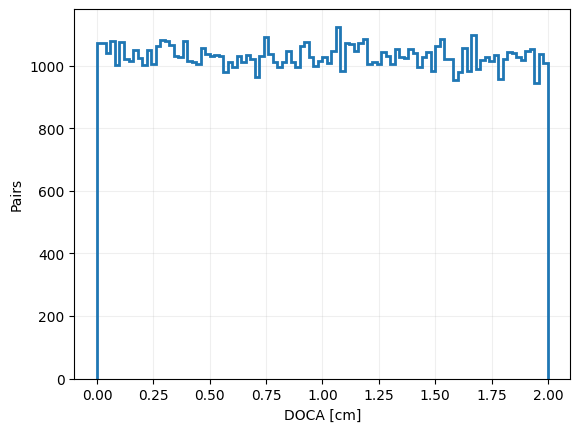

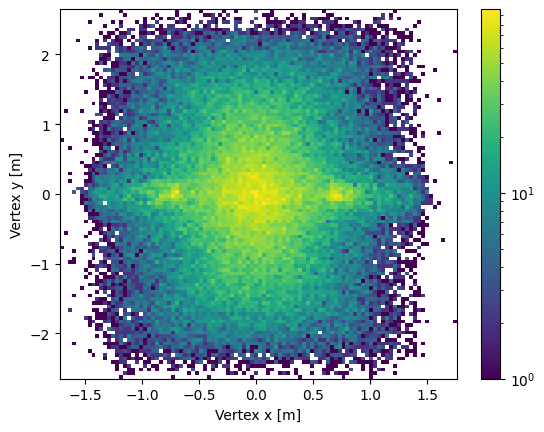

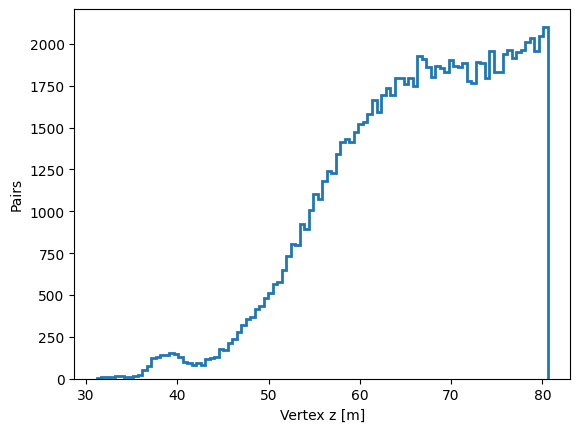

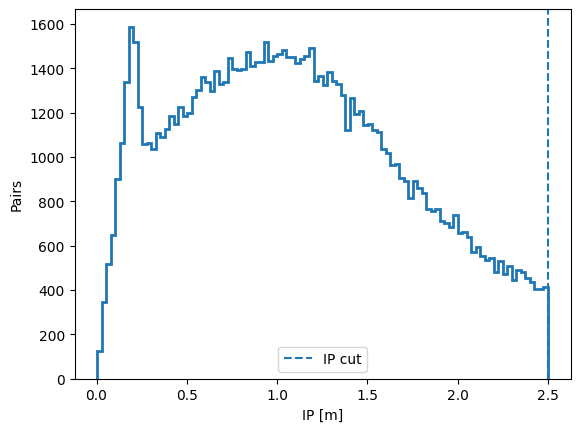

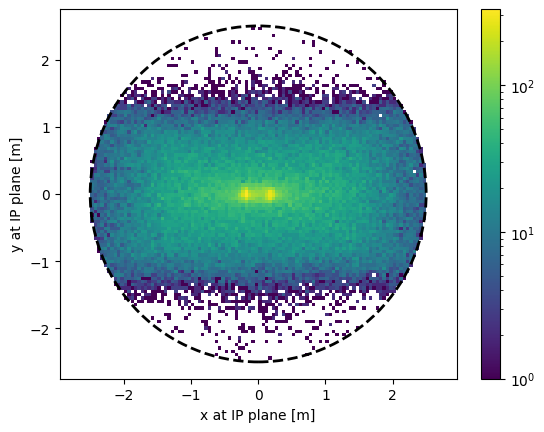

In [20]:


# ============================================================
# 18. MAIN
# ============================================================

def main():

    config = get_config()

    # ========================================================
    # FIND FILES
    # ========================================================

    files = get_files(
        config["input_pattern"]
    )

    # ========================================================
    # PROCESS EACH FILE INDEPENDENTLY
    # ========================================================

    file_results = []

    data_all = []

    pair_indx = []

    for filename in files:

        print()
        print("#" * 90)
        print(f"PROCESSING: {filename}")
        print("#" * 90)

        # ----------------------------------------------------
        # Load
        # ----------------------------------------------------

        raw_data = load_file(
            filename
        )

        # ----------------------------------------------------
        # Prepare
        # ----------------------------------------------------

        data = prepare_muons(
            raw_data
        )

        # ----------------------------------------------------
        # Single-muon cuts
        # ----------------------------------------------------

        muon_mask, cut_masks = (
            apply_single_muon_cuts(
                data,
                config
            )
        )

        single_flow = calculate_single_cutflow(
            cut_masks,
            len(data["x"]),
            data["weight"]
        )

        data_selected = select_muons(
            data,
            muon_mask
        )

        # ----------------------------------------------------
        # Pair analysis
        # ----------------------------------------------------

        result = analyse_pairs(
            data_selected,
            config
        )

        # ----------------------------------------------------
        # Keep data corresponding to pairs
        # ----------------------------------------------------

        pairs = result["pairs"]

        pair_data = {
            key: value[pairs]
            for key, value in data_selected.items()
        }

        # ----------------------------------------------------
        # Save all information for this file
        # ----------------------------------------------------

        file_result = make_file_summary(
            filename,
            data,
            single_flow,
            result
        )

        file_result["pair_data"] = pair_data
        
        file_results.append(
            file_result
        )

    # ========================================================
    # AVERAGE OVER FILES
    # ========================================================

    average = average_file_results(
        file_results
    )

    print_average_result(
        average,
        config
    )

    # ========================================================
    # PLOTS
    # ========================================================

    if config["check"]:

        make_plots(
            average,
            config
        )

    # ========================================================
    # RETURN EVERYTHING
    # ========================================================

    return (
        file_results,
        average,
        config
    )


# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":

    file_results, average, config = main()



In [22]:
file_results[1]

{'filename': 'outputs/TRY6_UBT_T1_seed_1.pkl',
 'seed': 1,
 'n_muons': 1322,
 'weighted_muons': np.float32(24955.15),
 'single_flow': [{'cut': 'Momentum',
   'before': np.int64(1322),
   'after': np.int64(951),
   'rejected': np.int64(371),
   'efficiency': np.float64(0.7193645990922845),
   'weighted_before': np.float32(24955.15),
   'weighted_after': np.float32(12514.133),
   'weighted_rejected': np.float32(12441.018),
   'weighted_efficiency': np.float32(0.5014649),
   'cumulative_efficiency': np.float64(0.7193645990922845),
   'cumulative_weighted_efficiency': np.float32(0.5014649)},
  {'cut': 'Timing detector',
   'before': np.int64(951),
   'after': np.int64(301),
   'rejected': np.int64(650),
   'efficiency': np.float64(0.31650893796004204),
   'weighted_before': np.float32(12514.133),
   'weighted_after': np.float32(4915.5977),
   'weighted_rejected': np.float32(7598.535),
   'weighted_efficiency': np.float32(0.3928037),
   'cumulative_efficiency': np.float64(0.2276853252647503